In [1]:
import numpy as np
import random
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from collections import Counter, deque
from tqdm import tqdm

from forward_backward import FBLearner
from continuous_four_rooms import ContinuousFourRooms, Point

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [2]:
env = ContinuousFourRooms(explorable=True, include_stay_action=False)

SIZE = env.size
STEP = 0.05
N_ACTIONS = len(env.actions)

print(f"size {SIZE} | actions {N_ACTIONS} ({', '.join(env.actions_str)}) "
      f"| threshold {env.threshold_distance} | wall blocks {len(env.wall_blocks)}")


def draw_walls(ax, lw=0):
    for blk in env.wall_blocks:
        ax.add_patch(patches.Rectangle((blk.xmin, blk.ymin), blk.xmax - blk.xmin, blk.ymax - blk.ymin,
                                       facecolor="0.15", edgecolor="0.15", zorder=3))
    ax.add_patch(patches.Rectangle((0, 0), SIZE, SIZE, fill=False, edgecolor="0.15", lw=2, zorder=3))
    ax.set_xlim(-0.02, SIZE + 0.02); ax.set_ylim(-0.02, SIZE + 0.02)
    ax.set_aspect("equal"); ax.axis("off")

size 1.0 | actions 4 (LEFT, RIGHT, UP, DOWN) | threshold 0.1 | wall blocks 7


## Checkpoint

In [3]:
loss_history = np.load("fb_four_rooms_nostay_loss.npy")
learner = FBLearner.from_checkpoint("fb_four_rooms_nostay.pt", device="cuda", buffer_device="cuda")

print(learner.config)

plt.figure(figsize=(6, 3))
plt.plot(loss_history)
plt.yscale("symlog"); plt.xlabel("update"); plt.ylabel("FB loss")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'fb_four_rooms_nostay_loss.npy'

In [4]:
def _prep(pts):
    x = np.asarray(pts, dtype=np.float32).reshape(-1, 2)
    return x


@torch.no_grad()
def fb_embed(pts, z=None, chunk=2048):
    '''(F averaged over actions, B) as CPU tensors of shape (n, embed_dim).'''
    x = np.asarray(pts, dtype=np.float32).reshape(-1, 2)
    fs, bs = [], []
    for i in range(0, len(x), chunk):
        xin = _prep(x[i:i + chunk])
        n = xin.shape[0]
        zz = None if z is None else z.reshape(1, -1).repeat(n, 1).to(learner.device)
        fs.append(learner.embed_F(xin, z=zz).mean(dim=2))
        bs.append(learner.embed_B(xin))
    return torch.cat(fs), torch.cat(bs)


@torch.no_grad()
def q_values(state, z):
    '''F(s, ., z)^T z for every action. Returns (n_actions,) on cpu.'''
    xin = _prep(np.asarray(state, dtype=np.float32).reshape(1, 2))
    z_t = z.reshape(1, -1)
    f = learner.embed_F(xin, z=z_t.to(learner.device))          # (1, D, A)
    return torch.einsum("bda, bd -> ba", f, z_t.cpu()).squeeze(0)

## Sample the reachable space

In [5]:
N_SAMPLE = 4000

sample = np.array([[p.x, p.y] for p in (env.sample_point() for _ in range(N_SAMPLE))],
                  dtype=np.float32)
print("sample:", sample.shape)

# Trajectory for empirical adjacency (explorable -> done is always False)
TRAJ_STEPS, EP_LEN = 40_000, 200
traj, traj_ep = [], []
state, ep = env.reset(), 0
for t in range(TRAJ_STEPS):
    traj.append(np.asarray(state, dtype=np.float32)); traj_ep.append(ep)
    state, _, _, _ = env.step(random.randrange(N_ACTIONS))
    if (t + 1) % EP_LEN == 0:
        state, ep = env.reset(), ep + 1
traj = np.array(traj, dtype=np.float32); traj_ep = np.array(traj_ep)
print("trajectory:", traj.shape, "episodes:", ep + 1)

sample: (4000, 2)
trajectory: (40000, 2) episodes: 201


In [6]:
f_all, b_all = fb_embed(sample)
raw = f_all @ b_all.T
self_sr = (f_all * b_all).sum(1)

print(f"clamped at eps:    {(raw < 1e-6).float().mean():.1%}")
print(f"strictly negative: {(raw < 0).float().mean():.1%}")
print(f"self-SR range:     {self_sr.min():.3f} .. {self_sr.max():.3f}")
print(f"self-SR <= 0:      {(self_sr <= 0).sum().item()} / {len(sample)}")

clamped at eps:    7.4%
strictly negative: 7.4%
self-SR range:     336.155 .. 1349.445
self-SR <= 0:      0 / 4000


## Symmetric SR distance

In [7]:
def sr_dist(f_a, b_a, f_b, b_b, eps=1e-6):
    sr_ab = torch.clamp(f_a @ b_b.T, min=eps)
    sr_ba = torch.clamp(f_b @ b_a.T, min=eps)
    sr_aa = torch.clamp((f_a * b_a).sum(1), min=eps)
    sr_bb = torch.clamp((f_b * b_b).sum(1), min=eps)

    d_ab = torch.log(sr_bb[None, :] / sr_ab)
    d_ba = torch.log(sr_aa[None, :] / sr_ba)
    return 0.5 * (d_ab + d_ba.T)


D = sr_dist(f_all, b_all, f_all, b_all).numpy()
print(f"negative entries in D: {(D < -1e-6).mean():.2%}")

D = np.maximum(D, 0.0)
np.fill_diagonal(D, 0.0)
print("D:", D.shape, "| median off-diagonal:", np.median(D[D > 0]).round(3))

negative entries in D: 0.00%
D: (4000, 4000) | median off-diagonal: 3.154


In [8]:
# helper cell to calc true distances

RES = 0.025
G = round(SIZE / RES)

centres = (np.arange(G) + 0.5) * RES
FREE = np.zeros((G, G), dtype=bool)
for i in range(G):
    for j in range(G):
        FREE[i, j] = not env._check_on_wall(Point(centres[i], centres[j]))

NBR = [[[] for _ in range(G)] for _ in range(G)]
for i in range(G):
    for j in range(G):
        if not FREE[i, j]:
            continue
        p = Point(centres[i], centres[j])
        for di, dj in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            a, b_ = i + di, j + dj
            if 0 <= a < G and 0 <= b_ < G and FREE[a, b_]:
                if not env._check_goes_through_wall(p, Point(centres[a], centres[b_])):
                    NBR[i][j].append((a, b_))

def to_cell(p):
    return (int(np.clip(p[0] / RES, 0, G - 1)), int(np.clip(p[1] / RES, 0, G - 1)))


def geodesic_steps(target_pts):
    '''BFS from a set of points. Returns (G, G) array of AGENT STEPS (not grid hops).'''
    dist = np.full((G, G), np.inf)
    dq = deque()
    for p in target_pts:
        c = to_cell(p)
        if FREE[c] and dist[c] == np.inf:
            dist[c] = 0.0
            dq.append(c)
    while dq:
        i, j = dq.popleft()
        for nb in NBR[i][j]:
            if dist[nb] == np.inf:
                dist[nb] = dist[i, j] + 1
                dq.append(nb)
    return dist * (RES / STEP)          # grid hops -> agent steps


def steps_from(dist_map, p):
    c = to_cell(p)
    return dist_map[c] if FREE[c] else np.inf


## Distance maps from a pinned anchor

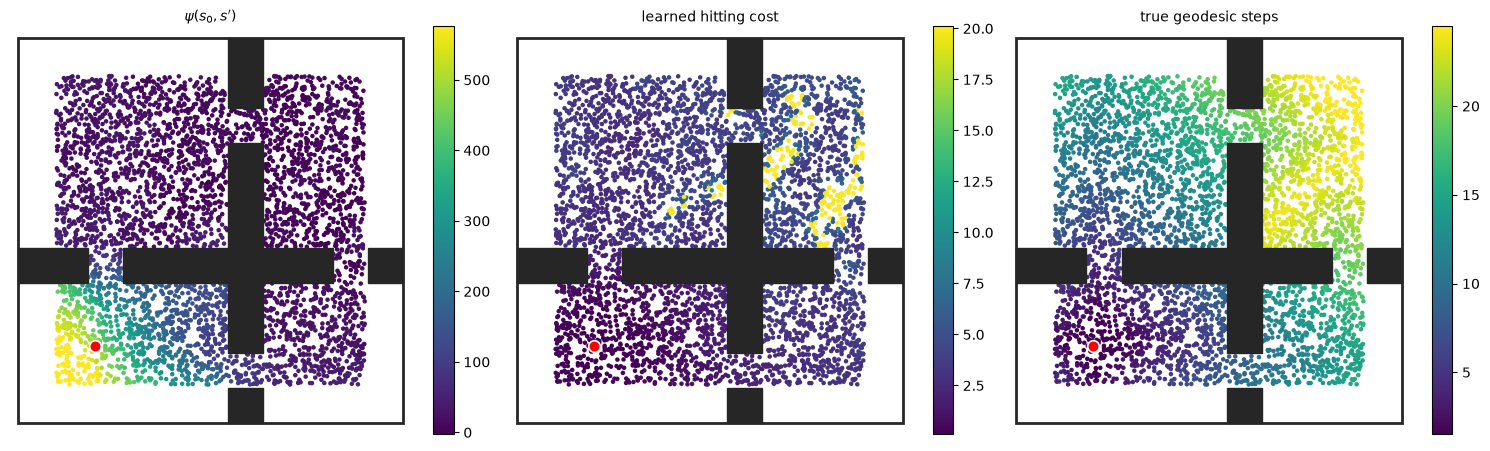

In [9]:
ANCHOR = np.array([0.2, 0.2], dtype=np.float32)     # bottom-left room; pinned, not sample[0]
f_a, b_a = fb_embed(ANCHOR[None, :])

psi_from_anchor = (f_a @ b_all.T).squeeze(0)
hit_cost = torch.log(torch.clamp(self_sr, min=1e-6) / torch.clamp(psi_from_anchor, min=1e-6))

dmap = geodesic_steps([ANCHOR])
geo_from_anchor = np.array([steps_from(dmap, s) for s in sample])


def pct_lims(c, lo=2, hi=98):
    c = np.asarray(c, dtype=float); fin = c[np.isfinite(c)]
    return dict(vmin=np.percentile(fin, lo), vmax=np.percentile(fin, hi))


panels = [
    (psi_from_anchor.numpy(), r"$\psi(s_0, s')$"),
    (hit_cost.numpy(), "learned hitting cost"),
    (geo_from_anchor, "true geodesic steps"),
]

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, (c, title) in zip(axs, panels):
    m = np.isfinite(c)
    sc = ax.scatter(sample[m, 0], sample[m, 1], c=np.asarray(c)[m], s=5, zorder=1, **pct_lims(c))
    ax.scatter(*ANCHOR, c="red", marker="o", s=70, edgecolors="white", lw=1.2, zorder=4)
    draw_walls(ax); ax.set_title(title, fontsize=10)
    fig.colorbar(sc, ax=ax, fraction=0.046)
fig.tight_layout(); plt.show()

## Cluster

In [10]:
NUM_CLUSTERS = 40

def kmedoids(D, k, n_iter=100):
    """Farthest-point init + Lloyd reassignment. Deterministic given D."""
    n = len(D)
    med = [int(D.sum(1).argmin())]
    while len(med) < k:
        med.append(int(D[:, med].min(1).argmax()))
    for _ in range(n_iter):
        lab = D[:, med].argmin(1)
        new = []
        for c in range(k):
            idx = np.where(lab == c)[0]
            if len(idx) == 0:
                new.append(med[c])
                continue
            new.append(int(idx[D[np.ix_(idx, idx)].sum(1).argmin()]))
        if new == med:
            break
        med = new
    lab = D[:, med].argmin(1)
    return np.array(med), lab, D[np.arange(n), np.array(med)[lab]].sum()

medoid_idx, labels, cost = kmedoids(D, NUM_CLUSTERS)
medoid_states = sample[medoid_idx]
f_med, b_med = fb_embed(medoid_states)

print("cluster sizes:", np.bincount(labels, minlength=NUM_CLUSTERS))
# print("medoids:\n", np.round(medoid_states, 3))

cluster sizes: [109  67 116 102 107  92  93 118 122 120  78  76 130  82 114  75 111 165
 115  81 111  73  98 106  88 110  98 107  98  98  91 115  79 114  69  80
 117 105  76  94]


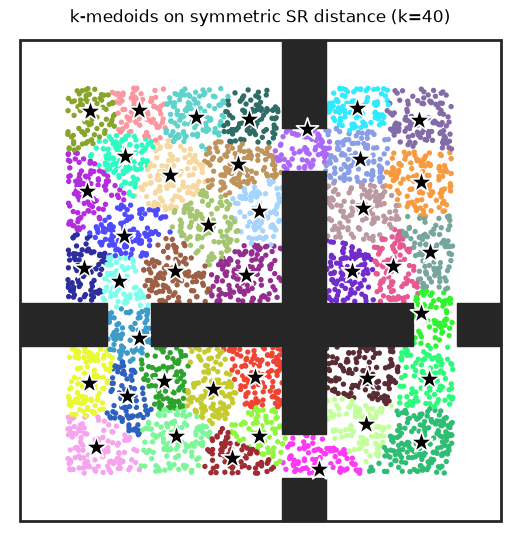

In [11]:
@torch.no_grad()
def classify(pts):
    '''Nearest medoid under the symmetric SR distance. A partition by construction.'''
    f, b = fb_embed(pts)
    return sr_dist(f, b, f_med, b_med).argmin(1).numpy()


def classify_one(p):
    return int(classify(np.asarray(p, dtype=np.float32).reshape(1, 2))[0])


labels_traj = classify(traj)

import distinctipy
colours = distinctipy.get_colors(NUM_CLUSTERS, pastel_factor=0.2)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(sample[:, 0], sample[:, 1], c=[colours[l] for l in labels], s=8, zorder=1)
ax.scatter(medoid_states[:, 0], medoid_states[:, 1], c="black", marker="*", s=280,
           edgecolors="white", lw=1.2, zorder=4)
draw_walls(ax)
ax.set_title(f"k-medoids on symmetric SR distance (k={NUM_CLUSTERS})")
plt.show()

## Cluster adjacency

In [12]:
MIN_CROSSINGS = 10 # Number of experienced transitions cluster to cluster to create an 'option'

counts = Counter()
for t in range(len(traj) - 1):
    if traj_ep[t] != traj_ep[t + 1]:
        continue
    a, b_ = int(labels_traj[t]), int(labels_traj[t + 1])
    if a != b_:
        counts[(a, b_)] += 1

cluster_edges = sorted([e for e, c in counts.items() if c >= MIN_CROSSINGS])
print(f"{len(cluster_edges)} edges (of {len(counts)} raw)")
for e in cluster_edges:
    print("  ", e, counts[e])

156 edges (of 174 raw)
   (0, 16) 65
   (0, 19) 46
   (0, 20) 70
   (0, 25) 26
   (0, 26) 82
   (0, 34) 50
   (0, 39) 18
   (1, 22) 31
   (1, 28) 83
   (1, 29) 69
   (2, 21) 47
   (2, 36) 81
   (3, 23) 91
   (3, 27) 69
   (4, 10) 21
   (4, 18) 91
   (4, 32) 64
   (5, 17) 107
   (5, 21) 39
   (5, 30) 97
   (5, 38) 24
   (6, 15) 24
   (6, 31) 164
   (6, 33) 68
   (7, 12) 52
   (7, 22) 58
   (7, 27) 76
   (7, 28) 23
   (7, 37) 68
   (8, 13) 76
   (8, 20) 51
   (8, 25) 81
   (9, 18) 100
   (9, 24) 34
   (9, 32) 48
   (9, 36) 30
   (9, 38) 114
   (10, 4) 13
   (10, 24) 21
   (10, 32) 28
   (10, 34) 51
   (11, 26) 67
   (11, 35) 100
   (11, 39) 63
   (12, 7) 52
   (12, 23) 108
   (12, 27) 44
   (12, 28) 120
   (13, 8) 67
   (13, 25) 97
   (13, 33) 91
   (14, 29) 67
   (14, 30) 95
   (15, 6) 30
   (15, 27) 56
   (15, 33) 41
   (16, 0) 62
   (16, 25) 74
   (16, 26) 17
   (16, 31) 57
   (16, 33) 46
   (16, 35) 13
   (16, 39) 86
   (17, 5) 96
   (17, 29) 129
   (17, 30) 89
   (18, 4) 90
   (18, 

## Option evaluation


In [13]:
INITIAL_STATES_PER_EDGE = 30
MAX_STEPS_PER_TRIAL = 30
EPSILON = 0.02


@torch.no_grad()
def target_z(cluster):
    _, b = fb_embed(sample[labels == cluster])
    return b.mean(dim=0)


def boltzmann_action(q, rng_np, temp=1.0, normalise=True):
    if len(q) == 1:
        return 0
    if normalise:
        q = (q - q.mean()) / q.std(unbiased=False).clamp(min=1e-8)
    p = torch.softmax((q - q.max()) / max(temp, 1e-8), dim=-1).double()
    if not torch.isfinite(p).all() or p.sum() <= 0:
        return int(q.argmax().item())
    return int(rng_np.choice(len(q), p=(p / p.sum()).numpy()))


def run_eval(policy="fb", seed=0, temp=1.0, normalise=True, max_steps: int = MAX_STEPS_PER_TRIAL):
    '''policy: "fb" (eps-greedy), "boltzmann" (sample), "random" (uniform).'''
    rng = random.Random(seed)
    rng_np = np.random.default_rng(seed)

    n_success = n_trials = n_skipped = 0
    steps, ratios, per_trial = [], [], []

    for i, j in tqdm(cluster_edges, desc=f"{policy}" + (f" T={temp}" if policy == "boltzmann" else "")):
        members_i = sample[labels == i]
        members_j = sample[labels == j]
        if len(members_i) == 0 or len(members_j) == 0:
            continue

        z = target_z(j)
        dmap = geodesic_steps(members_j)

        for _ in range(INITIAL_STATES_PER_EDGE):
            start = members_i[rng.randrange(len(members_i))]

            if classify_one(start) == j:
                n_skipped += 1
                continue
            best = steps_from(dmap, start)
            if not np.isfinite(best):
                n_skipped += 1
                continue

            state = env.reset(state=Point(*start.tolist()))
            n_trials += 1
            solved = 0

            for step in range(1, max_steps + 1):
                if policy == "random":
                    action = rng.randrange(N_ACTIONS)
                elif policy == "boltzmann":
                    action = boltzmann_action(q_values(state, z), rng_np, temp, normalise)
                elif rng.random() < EPSILON:
                    action = rng.randrange(N_ACTIONS)
                else:
                    action = int(q_values(state, z).argmax().item())

                state, _, _, _ = env.step(action)

                if classify_one(state) == j:
                    n_success += 1; solved = 1
                    steps.append(step); ratios.append(step / max(best, 1.0))
                    break

            per_trial.append((best, solved))

    per_trial = np.array(per_trial) if per_trial else np.zeros((0, 2))
    return {
        "policy": policy if policy != "boltzmann" else f"boltz(T={temp})",
        "rate": n_success / max(n_trials, 1),
        "trials": n_trials,
        "skipped": n_skipped,
        "median_steps": float(np.median(steps)) if steps else float("nan"),
        "median_ratio": float(np.median(ratios)) if ratios else float("nan"),
        "per_trial": per_trial,
    }

In [14]:
results = [run_eval("fb", seed=0), run_eval("random", seed=0)]
for T in (0.1, 0.3, 1.0, 3.0):
    results.append(run_eval("boltzmann", seed=0, temp=T))

for r in results:
    print(f"{r['policy']:>14}: {r['rate']:7.2%}  trials {r['trials']:5d}  skipped {r['skipped']:4d}  "
          f"median steps {r['median_steps']:6.1f}  vs oracle {r['median_ratio']:5.2f}x")

boltzmann T=3.0: 100%|﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿| 156/156 [00:57<00:00,  2.73it/s]

            fb:  97.43%  trials  4666  skipped   14  median steps    2.0  vs oracle  1.20x
        random:  54.57%  trials  4669  skipped   11  median steps    6.0  vs oracle  3.50x
  boltz(T=0.1):  98.14%  trials  4672  skipped    8  median steps    2.0  vs oracle  1.20x
  boltz(T=0.3):  99.06%  trials  4672  skipped    8  median steps    2.0  vs oracle  1.20x
  boltz(T=1.0):  99.85%  trials  4672  skipped    8  median steps    3.0  vs oracle  1.67x
  boltz(T=3.0):  92.08%  trials  4672  skipped    8  median steps    6.0  vs oracle  3.33x


In [15]:
rows = []
for h in (2, 5, 10, 20, 60):
    a, b_ = run_eval("fb", seed=1, max_steps=h), run_eval("random", seed=1, max_steps=h)
    rows.append((h, a["rate"], b_["rate"]))
    print(f"horizon {h:>2}:  fb {a['rate']:7.2%}   random {b_['rate']:7.2%}   "
          f"lift {a['rate'] - b_['rate']:+.2%}")

random: 100%|﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿| 156/156 [00:09<00:00, 16.94it/s]


horizon  2:  fb  58.99%   random  14.38%   lift +44.61%


random: 100%|﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿| 156/156 [00:16<00:00,  9.34it/s]


horizon  5:  fb  95.61%   random  26.10%   lift +69.52%


random: 100%|﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿| 156/156 [00:27<00:00,  5.71it/s]


horizon 10:  fb  96.51%   random  37.08%   lift +59.43%


random:  12%|﷿﷿﷿﷿﷿﷿        | 18/156 [00:05<00:38,  3.54it/s]


KeyboardInterrupt: 